## Homework - 20 Pandas Combining Objects

### Easy Questions

Q1. Inner Merge

Using ArtistId, merge the artists and albums tables.

Display the first 5 rows.

Expected columns may include:

-	ArtistId
-	Name
-	AlbumId
-	Title

In [56]:
from sqlalchemy import create_engine
import pandas as pd

engine = create_engine(r'sqlite:///data\chinook.db')

artists = pd.read_sql_table('artists', engine)
albums = pd.read_sql_table('albums', engine)

result = artists.merge(albums, on='ArtistId', how='inner')

result.head()

,ArtistId,Name,AlbumId,Title
0,1,AC/DC,1,For Those About To Rock We Salute You
1,1,AC/DC,4,Let There Be Rock
2,2,Accept,2,Balls to the Wall
3,2,Accept,3,Restless and Wild
4,3,Aerosmith,5,Big Ones


Q2. Track and Album Titles
Merge tracks and albums using AlbumId.
Display only:

-	track name
-	album title

Rename columns clearly:

-	TrackName
-	AlbumTitle

In [23]:
tracks = pd.read_sql_table('tracks', engine)

result = tracks.merge(albums, on='AlbumId')[['Name', 'Title']].rename(
    columns={'Name': 'TrackName', 'Title': 'AlbumTitle'}
)

result

,TrackName,AlbumTitle
0,For Those About To Rock (We Salute You),For Those About To Rock We Salute You
1,Balls to the Wall,Balls to the Wall
2,Fast As a Shark,Restless and Wild
3,Restless and Wild,Restless and Wild
4,Princess of the Dawn,Restless and Wild
...,...,...
3498,Pini Di Roma (Pinien Von Rom) \ I Pini Della V...,Respighi:Pines of Rome
3499,"String Quartet No. 12 in C Minor, D. 703 ""Quar...",Schubert: The Late String Quartets & String Qu...
3500,"L'orfeo, Act 3, Sinfonia (Orchestra)",Monteverdi: L'Orfeo
3501,"Quintet for Horn, Violin, 2 Violas, and Cello ...",Mozart: Chamber Music


Q3. Vertical Concatenation
Create two DataFrames:

-	first 10 rows from customers
-	last 10 rows from customers

Stack them vertically using pd.concat().
Reset the index after concatenation.

In [22]:
customers = pd.read_sql_table('customers', engine)

customers_1 = customers.head(10)
customers_2 = customers.tail(10)

result = pd.concat([customers_1, customers_2], ignore_index=True)

result

,CustomerId,FirstName,LastName,Company,Address,City,State,Country,PostalCode,Phone,Fax,Email,SupportRepId
0,1,Luís,Gonçalves,Embraer - Empresa Brasileira de Aeronáutica S.A.,"Av. Brigadeiro Faria Lima, 2170",São José dos Campos,SP,Brazil,12227-000,+55 (12) 3923-5555,+55 (12) 3923-5566,luisg@embraer.com.br,3
1,2,Leonie,Köhler,NaN,Theodor-Heuss-Straße 34,Stuttgart,NaN,Germany,70174,+49 0711 2842222,NaN,leonekohler@surfeu.de,5
2,3,François,Tremblay,NaN,1498 rue Bélanger,Montréal,QC,Canada,H2G 1A7,+1 (514) 721-4711,NaN,ftremblay@gmail.com,3
3,4,Bjørn,Hansen,NaN,Ullevålsveien 14,Oslo,NaN,Norway,0171,+47 22 44 22 22,NaN,bjorn.hansen@yahoo.no,4
4,5,František,Wichterlová,JetBrains s.r.o.,Klanova 9/506,Prague,NaN,Czech Republic,14700,+420 2 4172 5555,+420 2 4172 5555,frantisekw@jetbrains.com,4
5,6,Helena,Holý,NaN,Rilská 3174/6,Prague,NaN,Czech Republic,14300,+420 2 4177 0449,NaN,hholy@gmail.com,5
6,7,Astrid,Gruber,NaN,"Rotenturmstraße 4, 1010 Innere Stadt",Vienne,NaN,Austria,1010,+43 01 5134505,NaN,astrid.gruber@apple.at,5
7,8,Daan,Peeters,NaN,Grétrystraat 63,Brussels,NaN,Belgium,1000,+32 02 219 03 03,NaN,daan_peeters@apple.be,4
8,9,Kara,Nielsen,NaN,Sønder Boulevard 51,Copenhagen,NaN,Denmark,1720,+453 3331 9991,NaN,kara.nielsen@jubii.dk,4
9,10,Eduardo,Martins,Woodstock Discos,"Rua Dr. Falcão Filho, 155",São Paulo,SP,Brazil,01007-010,+55 (11) 3033-5446,+55 (11) 3033-4564,eduardo@woodstock.com.br,4


Q4. Horizontal Concatenation
Take the first 5 rows from the artists table.
Create:

-	DataFrame 1: ArtistId
-	DataFrame 2: Name

Concatenate them horizontally using:
pd.concat(..., axis=1)

In [26]:
df1 = artists['ArtistId'].head()
df2 = artists['Name'].head()

pd.concat([df1, df2], axis=1)

,ArtistId,Name
0,1,AC/DC
1,2,Accept
2,3,Aerosmith
3,4,Alanis Morissette
4,5,Alice In Chains


Q5. Basic .join()
Use .join() to combine albums and artists.
Steps:
1.	Set ArtistId as index in both DataFrames.
2.	Join albums with artists.
3.	Display album title and artist name.

In [29]:
albums_indexed = albums.set_index('ArtistId')
artists_indexed = artists.set_index('ArtistId')

result = (
    albums_indexed
    .join(artists_indexed, how='inner')
    [['Title', 'Name']]
    .rename(columns={
        'Title': 'AlbumTitle',
        'Name': 'ArtistName'
    })
)

result

,AlbumTitle,ArtistName
ArtistId,,
1,For Those About To Rock We Salute You,AC/DC
2,Balls to the Wall,Accept
2,Restless and Wild,Accept
1,Let There Be Rock,AC/DC
3,Big Ones,Aerosmith
...,...,...
226,Respighi:Pines of Rome,Eugene Ormandy
272,Schubert: The Late String Quartets & String Qu...,Emerson String Quartet
273,Monteverdi: L'Orfeo,"C. Monteverdi, Nigel Rogers - Chiaroscuro; Lon..."


Q6. Genre Mapping
Merge tracks and genres using GenreId.
Display:

    •	TrackId
    •	Track Name
    •	Genre Name

Use suffixes or renaming to avoid confusion between both Name columns.

In [34]:
genres = pd.read_sql_table('genres', engine)

result = (
    tracks
    .merge(genres, on='GenreId', suffixes=('_Track', '_Genre'))
    [['TrackId', 'Name_Track', 'Name_Genre']]
)

result

,TrackId,Name_Track,Name_Genre
0,1,For Those About To Rock (We Salute You),Rock
1,2,Balls to the Wall,Rock
2,3,Fast As a Shark,Rock
3,4,Restless and Wild,Rock
4,5,Princess of the Dawn,Rock
...,...,...,...
3498,3499,Pini Di Roma (Pinien Von Rom) \ I Pini Della V...,Classical
3499,3500,"String Quartet No. 12 in C Minor, D. 703 ""Quar...",Classical
3500,3501,"L'orfeo, Act 3, Sinfonia (Orchestra)",Classical
3501,3502,"Quintet for Horn, Violin, 2 Violas, and Cello ...",Classical


Q7. Media Type Mapping
Merge tracks and media_types using MediaTypeId.
Display:

    •	Track Name
    •	Media Type Name
    •	UnitPrice

In [ ]:
media_types = pd.read_sql_table('media_types', engine)

result = (
    tracks.merge(
        media_types, on='MediaTypeId', suffixes=('_Track', '_Media_Type')
    )[['Name_Track', 'Name_Media_Type', 'UnitPrice']]
)

result

,Name_Track,Name_Media_Type,UnitPrice
0,For Those About To Rock (We Salute You),MPEG audio file,0.99
1,Balls to the Wall,Protected AAC audio file,0.99
2,Fast As a Shark,Protected AAC audio file,0.99
3,Restless and Wild,Protected AAC audio file,0.99
4,Princess of the Dawn,Protected AAC audio file,0.99
...,...,...,...
3498,Pini Di Roma (Pinien Von Rom) \ I Pini Della V...,Protected AAC audio file,0.99
3499,"String Quartet No. 12 in C Minor, D. 703 ""Quar...",Protected AAC audio file,0.99
3500,"L'orfeo, Act 3, Sinfonia (Orchestra)",Protected AAC audio file,0.99
3501,"Quintet for Horn, Violin, 2 Violas, and Cello ...",Protected AAC audio file,0.99


Q8. Album Filter
Merge tracks and albums using AlbumId.
Filter only tracks from the album:
Unplugged
Display:

    •	Track Name
    •	Album Title

In [42]:
result = (
    tracks
    .merge(albums, on='AlbumId')
    [['Name', 'Title']]
    .rename(columns={
        'Name': 'TrackName',
        'Title': 'AlbumTitle'
    })
)

result[result['AlbumTitle'] == 'Unplugged']

,TrackName,AlbumTitle
908,Signe,Unplugged
909,Before You Accuse Me,Unplugged
910,Hey Hey,Unplugged
911,Tears In Heaven,Unplugged
912,Lonely Stranger,Unplugged
913,Nobody Knows You When You're Down & Out,Unplugged
914,Layla,Unplugged
915,Running On Faith,Unplugged
916,Walkin' Blues,Unplugged
917,Alberta,Unplugged


Q9. Artist Album Count
Merge artists and albums using ArtistId.
Then calculate how many albums each artist has.
Display:

    •	Artist Name
    •	AlbumCount

Sort by AlbumCount in descending order.

In [45]:
result = (
    artists.merge(
        albums, on='ArtistId'
    ).rename(columns={'Name': 'ArtistName'})
    .groupby('ArtistName', as_index=False)
    .agg(AlbumCount=('AlbumId', 'count'))
    .sort_values(by='AlbumCount', ascending=False)
)

result

,ArtistName,AlbumCount
91,Iron Maiden,21
107,Led Zeppelin,14
54,Deep Purple,11
125,Metallica,10
194,U2,10
...,...,...
199,Vinícius De Moraes,1
200,Wilhelm Kempff,1
201,Yehudi Menuhin,1
202,Yo-Yo Ma,1


Q10. Inner Column Logic with concat
Create two small DataFrames manually:
DataFrame 1 columns:
A, B, C
DataFrame 2 columns:
B, C, D
Use:
pd.concat([df1, df2], join='inner')
Answer this question in a comment:
Which columns remained after inner concat and why?

In [54]:
import pandas as pd

# DataFrame 1
df1 = pd.DataFrame({
    'A': [1, 2],
    'B': [3, 4],
    'C': [5, 6]
})

# DataFrame 2
df2 = pd.DataFrame({
    'B': [7, 8],
    'C': [9, 10],
    'D': [11, 12]
})

# Inner concat
result = pd.concat([df1, df2], join='inner', ignore_index=True)

print(result)

# Only columns B and C remained because they exist in both DataFrames.
# Columns A and D were removed since they are not common to both DataFrames.

   B   C
0  3   5
1  4   6
2  7   9
3  8  10


### Medium Questions

Q11. Left Join Analysis
Perform a left merge between artists and albums using ArtistId.
Find artists who do not have albums.
Display:

-	ArtistId
-	Artist Name

Hint:
Use how='left' and check missing album values.

In [ ]:
result = artists.merge(albums, on='ArtistId', how='left')

result = result[result['Title'].isna()]

result = result[['ArtistId', 'Name']].rename(
    columns={'Name': 'ArtistName'}
)

result

,ArtistId,ArtistName,AlbumId
50,25,Milton Nascimento & Bebeto,NaN
51,26,Azymuth,NaN
55,28,João Gilberto,NaN
56,29,Bebel Gilberto,NaN
57,30,Jorge Vercilo,NaN
...,...,...,...
327,192,DJ Dolores & Orchestra Santa Massa,NaN
328,193,Seu Jorge,NaN
329,194,Sabotage E Instituto,NaN
330,195,Stereo Maracana,NaN


Q12. Multi-Table Merge
Merge these tables:

-	tracks
-	albums
-	artists

Display:

-	Track Name
-	Album Title
-	Artist Name

Rename columns properly so the output is readable.

In [52]:
result = tracks.merge(albums, on='AlbumId')

result = result.merge(artists, on='ArtistId')

result[['Name_x', 'Title', 'Name_y']].rename(columns={
    'Name_x': 'Track Name',
    'Title': 'Album Title',
    'Name_y': 'Artist Name'
})

,Track Name,Album Title,Artist Name
0,For Those About To Rock (We Salute You),For Those About To Rock We Salute You,AC/DC
1,Balls to the Wall,Balls to the Wall,Accept
2,Fast As a Shark,Restless and Wild,Accept
3,Restless and Wild,Restless and Wild,Accept
4,Princess of the Dawn,Restless and Wild,Accept
...,...,...,...
3498,Pini Di Roma (Pinien Von Rom) \ I Pini Della V...,Respighi:Pines of Rome,Eugene Ormandy
3499,"String Quartet No. 12 in C Minor, D. 703 ""Quar...",Schubert: The Late String Quartets & String Qu...,Emerson String Quartet
3500,"L'orfeo, Act 3, Sinfonia (Orchestra)",Monteverdi: L'Orfeo,"C. Monteverdi, Nigel Rogers - Chiaroscuro; Lon..."
3501,"Quintet for Horn, Violin, 2 Violas, and Cello ...",Mozart: Chamber Music,Nash Ensemble


Q13. Invoice Revenue Calculation
Merge invoices and invoice_items using InvoiceId.
For each invoice, calculate total revenue using:
UnitPrice * Quantity

Display:

    •	InvoiceId
    •	CalculatedTotal
    •	InvoiceTotal

Compare your calculated total with the Total column from invoices.

In [70]:
invoices = pd.read_sql_table('invoices', engine)
invoice_items = pd.read_sql_table('invoice_items', engine)

invoice_items['CalculatedTotal'] = invoice_items['UnitPrice'] * invoice_items['Quantity']

result = invoices.merge(invoice_items, on='InvoiceId')

result = result.groupby('InvoiceId', as_index=False).agg(
        CalculatedTotal=('CalculatedTotal', 'sum'),
        InvoiceTotal=('Total', 'first')
    )

result[['InvoiceId', 'CalculatedTotal', 'InvoiceTotal']]

,InvoiceId,CalculatedTotal,InvoiceTotal
0,1,1.98,1.98
1,2,3.96,3.96
2,3,5.94,5.94
3,4,8.91,8.91
4,5,13.86,13.86
...,...,...,...
407,408,3.96,3.96
408,409,5.94,5.94
409,410,8.91,8.91
410,411,13.86,13.86


Q14. Germany Customer Spending
Merge customers and invoices using CustomerId.
Filter only customers from Germany.
For each German customer, calculate total spending.

Display:

    •	CustomerId
    •	FullName
    •	Country
    •	TotalSpent

Sort by TotalSpent in descending order.

In [79]:
result = customers.merge(invoices, on='CustomerId')

customers['FullName'] = customers['FirstName'] + ' ' + customers['LastName']

result = (
    customers
    .merge(invoices, on='CustomerId')
    .query("Country == 'Germany'")
    .groupby('CustomerId', as_index=False)
    .agg(
        FullName=('FullName', 'first'),
        Country=('Country', 'first'),
        TotalSpent=('Total', 'sum')
    )
    .sort_values('TotalSpent', ascending=False)
)

result

,CustomerId,FullName,Country,TotalSpent
2,37,Fynn Zimmermann,Germany,43.62
3,38,Niklas Schröder,Germany,37.62
1,36,Hannah Schneider,Germany,37.62
0,2,Leonie Köhler,Germany,37.62


Q15. Merge with Suffixes
Create two small DataFrames manually.
Example:

students_info

    •	StudentId
    •	Name
    •	Age

students_scores

    •	StudentId
    •	Name
    •	Score

Merge them using StudentId.
Use the suffixes parameter to separate duplicate Name columns.
Example:
suffixes=('_info', '_score')

In [80]:
students_info = pd.DataFrame({
    'StudentId': [1, 2, 3],
    'Name': ['Ali', 'Vali', 'Hasan'],
    'Age': [20, 21, 22]
})

students_scores = pd.DataFrame({
    'StudentId': [1, 2, 3],
    'Name': ['Ali', 'Vali', 'Hasan'],
    'Score': [95, 88, 91]
})

result = students_info.merge(
    students_scores,
    on='StudentId',
    suffixes=('_info', '_score')
)

result

,StudentId,Name_info,Age,Name_score,Score
0,1,Ali,20,Ali,95
1,2,Vali,21,Vali,88
2,3,Hasan,22,Hasan,91


Q16. Top Selling Genre
Merge these tables:

    •	invoice_items
    •	tracks
    •	genres

Calculate which genre has the highest number of sold tracks.
Use Quantity for sales count.
Display:

    •	Genre Name
    •	TotalQuantitySold

Sort from highest to lowest.

In [82]:
# Merge invoice_items with tracks
result = invoice_items.merge(tracks, on='TrackId')

# Merge with genres
result = result.merge(genres, on='GenreId')

# Calculate total quantity sold for each genre
result = (
    result.groupby('Name_y', as_index=False)
    .agg(
        TotalQuantitySold=('Quantity', 'sum')
    )
    .rename(columns={'Name_y': 'GenreName'})
    .sort_values('TotalQuantitySold', ascending=False)
)

result

,GenreName,TotalQuantitySold
17,Rock,835
12,Latin,386
13,Metal,264
1,Alternative & Punk,244
11,Jazz,80
2,Blues,61
22,TV Shows,47
4,Classical,41
15,R&B/Soul,41
16,Reggae,30


Q17. Employee Hierarchy Self-Join
Using the employees table, perform a self-join.

Use:

    •	EmployeeId
    •	ReportsTo

Display:

    •	Employee Full Name
    •	Manager Full Name
    
Employees without a manager should still be handled properly.


In [86]:
employees = pd.read_sql_table('employees', engine)

employees['EmployeeFullName'] = (
    employees['FirstName'] + ' ' + employees['LastName']
)

managers = employees[['EmployeeId', 'EmployeeFullName']].rename(
    columns={
        'EmployeeId': 'ReportsTo',
        'EmployeeFullName': 'ManagerFullName'
    }
)

result = (
    employees.merge(managers, on='ReportsTo', how='left')
    [['EmployeeFullName', 'ManagerFullName']]
)

result

,EmployeeFullName,ManagerFullName
0,Andrew Adams,NaN
1,Nancy Edwards,Andrew Adams
2,Jane Peacock,Nancy Edwards
3,Margaret Park,Nancy Edwards
4,Steve Johnson,Nancy Edwards
5,Michael Mitchell,Andrew Adams
6,Robert King,Michael Mitchell
7,Laura Callahan,Michael Mitchell


Q18. Cross Join
Create two DataFrames manually.
Cities:
Tashkent, Samarkand, Bukhara, Andijan, Fergana
Products:
Laptop, Phone, Tablet
Create all possible city-product combinations using cross join.
Expected number of rows:
5 × 3 = 15 rows

In [87]:
cities = pd.DataFrame({
    'City': ['Tashkent', 'Samarkand', 'Bukhara', 'Andijan', 'Fergana']
})

products = pd.DataFrame({
    'Product': ['Laptop', 'Phone', 'Tablet']
})

result = cities.merge(products, how='cross')

result

,City,Product
0,Tashkent,Laptop
1,Tashkent,Phone
2,Tashkent,Tablet
3,Samarkand,Laptop
4,Samarkand,Phone
5,Samarkand,Tablet
6,Bukhara,Laptop
7,Bukhara,Phone
8,Bukhara,Tablet
9,Andijan,Laptop


Q19. Merge Validation
Merge artists and albums using:
validate='one_to_many'
Explain in a comment why this validation is correct.
Question:
Why is one artist connected to many albums?

In [89]:
result = artists.merge(
    albums,
    on='ArtistId',
    how='inner',
    validate='one_to_many'
)

result

# validate='one_to_many' is correct because each ArtistId appears only once
# in the artists table, but the same ArtistId can appear many times in
# the albums table. One artist can release multiple albums.

,ArtistId,Name,AlbumId,Title
0,1,AC/DC,1,For Those About To Rock We Salute You
1,1,AC/DC,4,Let There Be Rock
2,2,Accept,2,Balls to the Wall
3,2,Accept,3,Restless and Wild
4,3,Aerosmith,5,Big Ones
...,...,...,...,...
342,271,"Mela Tenenbaum, Pro Musica Prague & Richard Kapp",342,"Locatelli: Concertos for Violin, Strings and C..."
343,272,Emerson String Quartet,344,Schubert: The Late String Quartets & String Qu...
344,273,"C. Monteverdi, Nigel Rogers - Chiaroscuro; Lon...",345,Monteverdi: L'Orfeo
345,274,Nash Ensemble,346,Mozart: Chamber Music


Q20. Latest Year Purchases
Do not manually choose a random year.
First, convert InvoiceDate to datetime.
Then find the latest available year in the invoices table.
Filter invoices from that latest year and merge them with customers.

Display:

    •	CustomerId
    •	FullName
    •	Country
    •	InvoiceDate
    •	Total

In [90]:
invoices['InvoiceDate'] = pd.to_datetime(invoices['InvoiceDate'])

latest_year = invoices['InvoiceDate'].dt.year.max()

customers['FullName'] = (
    customers['FirstName'] + ' ' + customers['LastName']
)

latest_invoices = invoices[
    invoices['InvoiceDate'].dt.year == latest_year
]

result = (
    latest_invoices
    .merge(customers, on='CustomerId')
    [['CustomerId', 'FullName', 'Country', 'InvoiceDate', 'Total']]
    .sort_values('InvoiceDate')
)

result

,CustomerId,FullName,Country,InvoiceDate,Total
0,30,Edward Francis,Canada,2013-01-02,8.91
1,39,Camille Bernard,France,2013-01-07,13.86
2,53,Phil Hughes,United Kingdom,2013-01-15,0.99
3,54,Steve Murray,United Kingdom,2013-01-28,1.98
4,56,Diego Gutiérrez,Argentina,2013-01-28,1.98
...,...,...,...,...,...
75,25,Victor Stevens,USA,2013-12-05,3.96
76,29,Robert Brown,Canada,2013-12-06,5.94
77,35,Madalena Sampaio,Portugal,2013-12-09,8.91
78,44,Terhi Hämäläinen,Finland,2013-12-14,13.86


### Hard Questions

Q21. Global Music Intelligence Report
Using these tables:

    •	customers
    •	invoices
    •	invoice_items
    •	tracks
    •	genres
    •	albums
    •	artists

Create a customer-level music report.
Your final report should include:

    •	CustomerId
    •	Customer Full Name
    •	Country
    •	TotalSpent
    •	TotalTracksPurchased
    •	MostPurchasedGenre
    •	UniqueArtistsPurchased
    •	SpendingRank
    
Requirements:
1.	Merge all required tables using Pandas.
2.	Calculate total spending per customer.
3.	Find each customer’s most purchased genre.
4.	Count how many unique artists each customer bought.
5.	Rank customers by total spending.
6.	Export the final result as:
global_music_report.csv

In [92]:
from sqlalchemy import create_engine
import pandas as pd

# Database connection
engine = create_engine(r"sqlite:///data\chinook.db")

# Read tables
customers = pd.read_sql_table("customers", engine)
invoices = pd.read_sql_table("invoices", engine)
invoice_items = pd.read_sql_table("invoice_items", engine)
tracks = pd.read_sql_table("tracks", engine)
genres = pd.read_sql_table("genres", engine)
albums = pd.read_sql_table("albums", engine)
artists = pd.read_sql_table("artists", engine)

# Create customer full name
customers["FullName"] = (
    customers["FirstName"] + " " + customers["LastName"]
)

# Merge all tables
df = (
    customers
    .merge(invoices, on="CustomerId")
    .merge(invoice_items, on="InvoiceId")
    .merge(tracks, on="TrackId", suffixes=("", "_Track"))
    .merge(genres, on="GenreId", suffixes=("", "_Genre"))
    .merge(albums, on="AlbumId", suffixes=("", "_Album"))
    .merge(artists, on="ArtistId", suffixes=("", "_Artist"))
)

# ---------------------------------------------------
# 1. Total spending per customer
# ---------------------------------------------------
total_spent = (
    df.groupby("CustomerId", as_index=False)
      .agg(TotalSpent=("Total", "sum"))
)

# Invoice Total is repeated after merge,
# so keep one value per invoice first.
invoice_totals = (
    invoices.groupby("CustomerId", as_index=False)
            .agg(TotalSpent=("Total", "sum"))
)

# ---------------------------------------------------
# 2. Total tracks purchased
# ---------------------------------------------------
tracks_purchased = (
    df.groupby("CustomerId", as_index=False)
      .agg(TotalTracksPurchased=("Quantity", "sum"))
)

# ---------------------------------------------------
# 3. Most purchased genre
# ---------------------------------------------------
genre_sales = (
    df.groupby(["CustomerId", "Name_Genre"], as_index=False)
      .agg(QuantitySold=("Quantity", "sum"))
)

most_genre = (
    genre_sales
    .sort_values(
        ["CustomerId", "QuantitySold"],
        ascending=[True, False]
    )
    .drop_duplicates("CustomerId")
    [["CustomerId", "Name_Genre"]]
    .rename(columns={"Name_Genre": "MostPurchasedGenre"})
)

# ---------------------------------------------------
# 4. Unique artists purchased
# ---------------------------------------------------
unique_artists = (
    df.groupby("CustomerId", as_index=False)
      .agg(UniqueArtistsPurchased=("ArtistId", "nunique"))
)

# ---------------------------------------------------
# 5. Combine everything
# ---------------------------------------------------
report = (
    customers[["CustomerId", "FullName", "Country"]]
    .merge(invoice_totals, on="CustomerId")
    .merge(tracks_purchased, on="CustomerId")
    .merge(most_genre, on="CustomerId")
    .merge(unique_artists, on="CustomerId")
)

# ---------------------------------------------------
# 6. Spending Rank
# ---------------------------------------------------
report["SpendingRank"] = (
    report["TotalSpent"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

# Sort by spending
report = report.sort_values(
    "TotalSpent",
    ascending=False
)

# ---------------------------------------------------
# 7. Export
# ---------------------------------------------------
report.to_csv(
    "global_music_report.csv",
    index=False
)

report

,CustomerId,FullName,Country,TotalSpent,TotalTracksPurchased,MostPurchasedGenre,UniqueArtistsPurchased,SpendingRank
5,6,Helena Holý,Czech Republic,49.62,38,Rock,13,1
25,26,Richard Cunningham,USA,47.62,38,Rock,11,2
56,57,Luis Rojas,Chile,46.62,38,Rock,15,3
44,45,Ladislav Kovács,Hungary,45.62,38,Rock,18,4
45,46,Hugh O'Reilly,Ireland,45.62,38,Rock,11,4
27,28,Julia Barnett,USA,43.62,38,Rock,14,5
36,37,Fynn Zimmermann,Germany,43.62,38,Rock,15,5
23,24,Frank Ralston,USA,43.62,38,Rock,19,5
6,7,Astrid Gruber,Austria,42.62,38,Rock,11,6
24,25,Victor Stevens,USA,42.62,38,Rock,15,6


Q22. Unsold Tracks Investigation Report
Using these tables:

    •	tracks
    •	invoice_items
    •	albums
    •	artists
    •	genres

Find tracks that were never sold.
Your final report should include:

    •	TrackId
    •	Track Name
    •	Genre Name
    •	Artist Name
    •	Album Title
    •	UnitPrice

Also calculate a genre-level summary:

    •	Genre Name
    •	TotalTracks
    •	UnsoldTracks
    •	UnsoldPercentage
    
Requirements:
1.	Use left merge between tracks and invoice_items.
2.	Identify tracks where no invoice item exists.
3.	Merge with albums, artists, and genres to make the report readable.
4.	Sort genres by highest unsold percentage.
5.	Export unsold track details as:
unsold_tracks_report.csv
6.	Export genre summary as:
unsold_genre_summary.csv

In [96]:
from sqlalchemy import create_engine
import pandas as pd

# Database connection
engine = create_engine(r"sqlite:///data\chinook.db")

# Read tables
tracks = pd.read_sql_table("tracks", engine)
invoice_items = pd.read_sql_table("invoice_items", engine)
albums = pd.read_sql_table("albums", engine)
artists = pd.read_sql_table("artists", engine)
genres = pd.read_sql_table("genres", engine)

# ----------------------------------------------------
# Rename columns to avoid duplicate names
# ----------------------------------------------------

tracks = tracks.rename(columns={
    "Name": "TrackName",
    "UnitPrice": "TrackPrice"
})

albums = albums.rename(columns={
    "Title": "AlbumTitle"
})

artists = artists.rename(columns={
    "Name": "ArtistName"
})

genres = genres.rename(columns={
    "Name": "GenreName"
})

# ----------------------------------------------------
# Left Merge
# ----------------------------------------------------

result = tracks.merge(
    invoice_items,
    on="TrackId",
    how="left"
)

# ----------------------------------------------------
# Unsold Tracks
# ----------------------------------------------------

unsold = result[result["InvoiceLineId"].isna()]

# ----------------------------------------------------
# Merge Album
# ----------------------------------------------------

unsold = unsold.merge(
    albums,
    on="AlbumId",
    how="left"
)

# ----------------------------------------------------
# Merge Artist
# ----------------------------------------------------

unsold = unsold.merge(
    artists,
    on="ArtistId",
    how="left"
)

# ----------------------------------------------------
# Merge Genre
# ----------------------------------------------------

unsold = unsold.merge(
    genres,
    on="GenreId",
    how="left"
)

# ----------------------------------------------------
# Final Unsold Report
# ----------------------------------------------------

unsold_report = unsold[
    [
        "TrackId",
        "TrackName",
        "GenreName",
        "ArtistName",
        "AlbumTitle",
        "TrackPrice"
    ]
]

print(unsold_report.head())

# Export

unsold_report.to_csv(
    "unsold_tracks_report.csv",
    index=False
)

# ====================================================
# Genre Summary
# ====================================================

# Total tracks per genre

total_tracks = (
    tracks
    .merge(genres, on="GenreId")
    .groupby("GenreName", as_index=False)
    .agg(
        TotalTracks=("TrackId", "count")
    )
)

# Unsold tracks per genre

unsold_tracks = (
    unsold
    .groupby("GenreName", as_index=False)
    .agg(
        UnsoldTracks=("TrackId", "count")
    )
)

# Merge summaries

genre_summary = total_tracks.merge(
    unsold_tracks,
    on="GenreName",
    how="left"
)

genre_summary["UnsoldTracks"] = (
    genre_summary["UnsoldTracks"]
    .fillna(0)
    .astype(int)
)

genre_summary["UnsoldPercentage"] = (
    genre_summary["UnsoldTracks"]
    / genre_summary["TotalTracks"]
    * 100
).round(2)

genre_summary = genre_summary.sort_values(
    "UnsoldPercentage",
    ascending=False
)

print(genre_summary)

# Export

genre_summary.to_csv(
    "unsold_genre_summary.csv",
    index=False
)

   TrackId          TrackName GenreName ArtistName  \
0        7    Let's Get It Up      Rock      AC/DC   
1       11             C.O.D.      Rock      AC/DC   
2       17  Let There Be Rock      Rock      AC/DC   
3       18     Bad Boy Boogie      Rock      AC/DC   
4       22  Whole Lotta Rosie      Rock      AC/DC   

                              AlbumTitle  TrackPrice  
0  For Those About To Rock We Salute You        0.99  
1  For Those About To Rock We Salute You        0.99  
2                      Let There Be Rock        0.99  
3                      Let There Be Rock        0.99  
4                      Let There Be Rock        0.99  
             GenreName  TotalTracks  UnsoldTracks  UnsoldPercentage
14               Opera            1             1            100.00
0          Alternative           40            26             65.00
8    Electronica/Dance           30            19             63.33
21     Science Fiction           13             8             61.54
7    

Q23. Employee Revenue Intelligence Report
Using these tables:

    •	employees
    •	customers
    •	invoices

Create an employee performance report.
Each customer has a support representative:
customers.SupportRepId = employees.EmployeeId
Your final report should include:

    •	EmployeeId
    •	Employee Full Name
    •	Title
    •	TotalCustomers
    •	TotalRevenue
    •	AverageRevenuePerCustomer
    •	RevenueRank
    •	PerformanceStatus

Rules:
If TotalRevenue >= average employee revenue:
    PerformanceStatus = "Above Average"
else:
    PerformanceStatus = "Below Average"
Requirements:
1.	Merge employees with customers.
2.	Merge the result with invoices.
3.	Calculate total revenue handled by each employee.
4.	Calculate average revenue per customer.
5.	Rank employees by revenue.
6.	Export the result as:
employee_revenue_dashboard.csv

2 Questions from Next Topic: Matplotlib
These questions are for pre-study.
Main focus is still Pandas grouping and simple plotting.

In [97]:
from sqlalchemy import create_engine
import pandas as pd
import numpy as np

# Database connection
engine = create_engine(r"sqlite:///data\chinook.db")

# Read tables
employees = pd.read_sql_table("employees", engine)
customers = pd.read_sql_table("customers", engine)
invoices = pd.read_sql_table("invoices", engine)

# ----------------------------------------------------
# Create Employee Full Name
# ----------------------------------------------------

employees["EmployeeFullName"] = (
    employees["FirstName"] + " " + employees["LastName"]
)

# ----------------------------------------------------
# Merge employees -> customers
# ----------------------------------------------------

result = employees.merge(
    customers,
    left_on="EmployeeId",
    right_on="SupportRepId",
    how="left"
)

# ----------------------------------------------------
# Merge invoices
# ----------------------------------------------------

result = result.merge(
    invoices,
    on="CustomerId",
    how="left"
)

# ----------------------------------------------------
# Employee Revenue Report
# ----------------------------------------------------

report = (
    result.groupby(
        ["EmployeeId", "EmployeeFullName", "Title"],
        as_index=False
    )
    .agg(
        TotalCustomers=("CustomerId", "nunique"),
        TotalRevenue=("Total", "sum")
    )
)

# ----------------------------------------------------
# Average Revenue Per Customer
# ----------------------------------------------------

report["AverageRevenuePerCustomer"] = (
    report["TotalRevenue"] / report["TotalCustomers"]
).round(2)

# ----------------------------------------------------
# Revenue Rank
# ----------------------------------------------------

report["RevenueRank"] = (
    report["TotalRevenue"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

# ----------------------------------------------------
# Average Employee Revenue
# ----------------------------------------------------

average_revenue = report["TotalRevenue"].mean()

# ----------------------------------------------------
# Performance Status
# ----------------------------------------------------

report["PerformanceStatus"] = np.where(
    report["TotalRevenue"] >= average_revenue,
    "Above Average",
    "Below Average"
)

# ----------------------------------------------------
# Sort
# ----------------------------------------------------

report = report.sort_values(
    "RevenueRank"
)

# ----------------------------------------------------
# Export
# ----------------------------------------------------

report.to_csv(
    "employee_revenue_dashboard.csv",
    index=False
)

print(report)

   EmployeeId  EmployeeFullName                Title  TotalCustomers  \
2           3      Jane Peacock  Sales Support Agent              21   
3           4     Margaret Park  Sales Support Agent              20   
4           5     Steve Johnson  Sales Support Agent              18   
1           2     Nancy Edwards        Sales Manager               0   
0           1      Andrew Adams      General Manager               0   
5           6  Michael Mitchell           IT Manager               0   
6           7       Robert King             IT Staff               0   
7           8    Laura Callahan             IT Staff               0   

   TotalRevenue  AverageRevenuePerCustomer  RevenueRank PerformanceStatus  
2        833.04                      39.67            1     Above Average  
3        775.40                      38.77            2     Above Average  
4        720.16                      40.01            3     Above Average  
1          0.00                        NaN     

### 2 Questions from Next Topic: Matplotlib
### These questions are for pre-study.
### Main focus is still Pandas grouping and simple plotting.

Q24. Sales by Country Bar Chart
Using the invoices table:
1.	Group invoices by BillingCountry.
2.	Count number of invoices per country.
3.	Create a bar chart using:

df.plot(kind='bar')

Chart title:

Number of Invoices by Country

Matplotlib is building the font cache; this may take a moment.


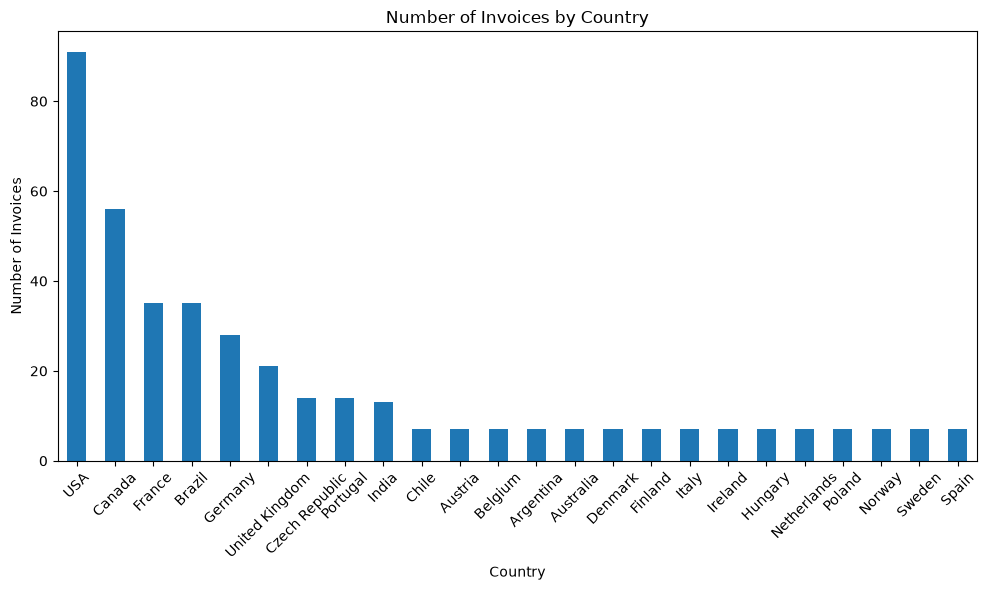

In [98]:
from sqlalchemy import create_engine
import pandas as pd
import matplotlib.pyplot as plt

# Database connection
engine = create_engine(r"sqlite:///data\chinook.db")

# Read table
invoices = pd.read_sql_table("invoices", engine)

# Group by BillingCountry
df = (
    invoices
    .groupby("BillingCountry", as_index=False)
    .agg(InvoiceCount=("InvoiceId", "count"))
    .sort_values("InvoiceCount", ascending=False)
)

# Create bar chart
df.plot(
    x="BillingCountry",
    y="InvoiceCount",
    kind="bar",
    legend=False,
    figsize=(10, 6)
)

# Chart title
plt.title("Number of Invoices by Country")

# Axis labels
plt.xlabel("Country")
plt.ylabel("Number of Invoices")

# Rotate country names
plt.xticks(rotation=45)

# Adjust layout
plt.tight_layout()

# Show chart
plt.show()

Q25. Monthly Sales Trend Line Chart
Using the invoices table:
1.	Convert InvoiceDate to datetime.
2.	Create a YearMonth column.
3.	Group by month.
4.	Calculate total sales per month.
5.	Create a line chart.

Chart title:

Monthly Sales Trend

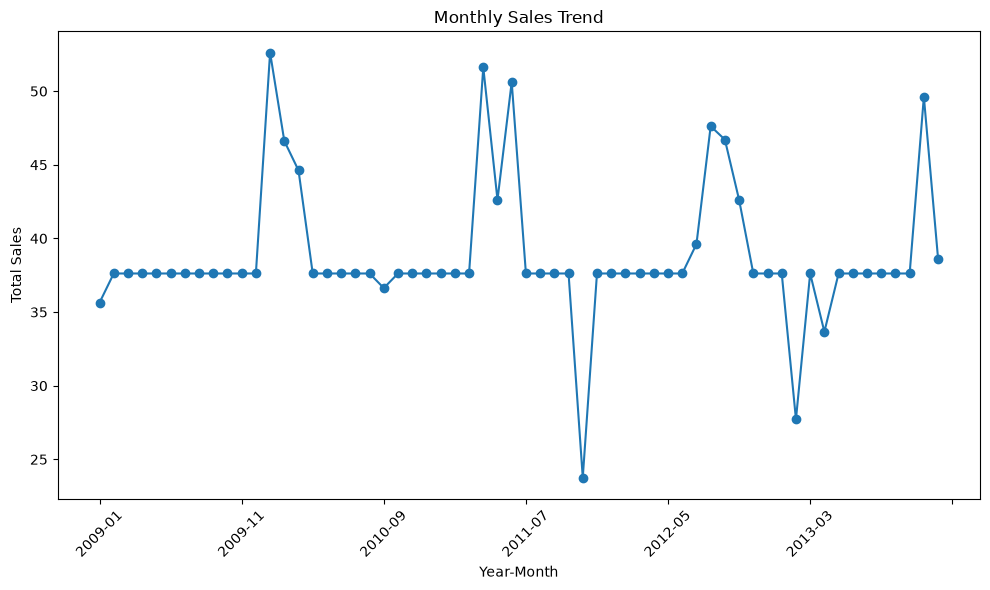

In [99]:
from sqlalchemy import create_engine
import pandas as pd
import matplotlib.pyplot as plt

# Database connection
engine = create_engine(r"sqlite:///data\chinook.db")

# Read table
invoices = pd.read_sql_table("invoices", engine)

# Convert InvoiceDate to datetime
invoices["InvoiceDate"] = pd.to_datetime(invoices["InvoiceDate"])

# Create YearMonth column
invoices["YearMonth"] = invoices["InvoiceDate"].dt.to_period("M").astype(str)

# Group by month and calculate total sales
monthly_sales = (
    invoices
    .groupby("YearMonth", as_index=False)
    .agg(TotalSales=("Total", "sum"))
)

# Create line chart
monthly_sales.plot(
    x="YearMonth",
    y="TotalSales",
    kind="line",
    marker="o",
    figsize=(10, 6),
    legend=False
)

# Chart title
plt.title("Monthly Sales Trend")

# Axis labels
plt.xlabel("Year-Month")
plt.ylabel("Total Sales")

# Rotate x-axis labels
plt.xticks(rotation=45)

# Adjust layout
plt.tight_layout()

# Show chart
plt.show()